In [1]:
!pip install -q langgraph langchain-anthropic

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.2/65.2 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 28.3 MB/s eta 0:00:00


In [2]:
import os
from typing import TypedDict
from langgraph.graph import StateGraph, END

MAX_REVISIONS = 3

class State(TypedDict):
    question: str
    plan: str
    research: str
    draft: str
    feedback: str
    approved: bool
    revisions: int

USE_LLM = bool(os.getenv("ANTHROPIC_API_KEY"))
if USE_LLM:
    from langchain_anthropic import ChatAnthropic
    llm = ChatAnthropic(model="claude-sonnet-5-5", temperature=0)

def ask(prompt, fake):
    return llm.invoke(prompt).content if USE_LLM else fake

def planner(state: State) -> dict:
    return {"plan": ask(f"Write a 3-bullet plan to answer: {state['question']}",
                        "1) Define topic 2) Gather facts 3) Summarize")}

def researcher(state: State) -> dict:
    return {"research": ask(f"Plan:\n{state['plan']}\nList key facts for: {state['question']}",
                            "Fact A; Fact B; Fact C (dummy)")}

def writer(state: State) -> dict:
    draft = ask(f"Question: {state['question']}\nResearch: {state['research']}\n"
                f"Feedback: {state.get('feedback','')}\nWrite a short answer.",
                f"Draft v{state['revisions']+1} (dummy)")
    return {"draft": draft, "revisions": state["revisions"] + 1}

def reviewer(state: State) -> dict:
    verdict = ask(f"Review:\n{state['draft']}\nReply 'APPROVE' if good, else one-line feedback.",
                  "APPROVE" if state["revisions"] >= 2 else "Add more detail.")
    ok = verdict.strip().upper().startswith("APPROVE")
    return {"approved": ok, "feedback": "" if ok else verdict}

def route_after_review(state: State) -> str:
    return "done" if state["approved"] or state["revisions"] >= MAX_REVISIONS else "revise"

g = StateGraph(State)
g.add_node("planner", planner)
g.add_node("researcher", researcher)
g.add_node("writer", writer)
g.add_node("reviewer", reviewer)
g.set_entry_point("planner")
g.add_edge("planner", "researcher")
g.add_edge("researcher", "writer")
g.add_edge("writer", "reviewer")
g.add_conditional_edges("reviewer", route_after_review, {"revise": "writer", "done": END})
app = g.compile()

init = {"question": "What is LangGraph?", "revisions": 0, "approved": False, "feedback": ""}
for step in app.stream(init, stream_mode="updates"):
    for node, update in step.items():
        print(f"[{node}] -> {update}")

final = app.invoke(init)
print("\nFINAL ANSWER:", final["draft"])

[planner] -> {'plan': '1) Define topic 2) Gather facts 3) Summarize'}
[researcher] -> {'research': 'Fact A; Fact B; Fact C (dummy)'}
[writer] -> {'draft': 'Draft v1 (dummy)', 'revisions': 1}
[reviewer] -> {'approved': False, 'feedback': 'Add more detail.'}
[writer] -> {'draft': 'Draft v2 (dummy)', 'revisions': 2}
[reviewer] -> {'approved': True, 'feedback': ''}

FINAL ANSWER: Draft v2 (dummy)


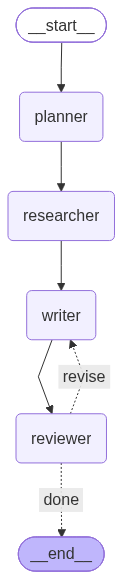

In [3]:
from IPython.display import Image, display
display(Image(app.get_graph().draw_mermaid_png()))

more advancement

In [6]:
import os
from typing import TypedDict
from langgraph.graph import StateGraph, END
from langgraph.checkpoint.memory import MemorySaver

MAX_REVISIONS = 3

# ---------- STATE ----------
class State(TypedDict):
    question: str
    route: str
    plan: str
    research_a: str
    research_b: str
    draft: str
    feedback: str
    approved: bool
    revisions: int

# ---------- LLM (optional) ----------
USE_LLM = bool(os.getenv("ANTHROPIC_API_KEY"))
if USE_LLM:
    from langchain_anthropic import ChatAnthropic
    llm = ChatAnthropic(model="claude-sonnet-5-5", temperature=0)

def ask(prompt, fake):
    return llm.invoke(prompt).content if USE_LLM else fake

# ---------- NODES ----------
def router(state: State) -> dict:
    d = ask(f"Does this need research? Reply only RESEARCH or DIRECT: {state['question']}",
            "RESEARCH" if len(state["question"].split()) > 3 else "DIRECT")
    return {"route": d}

def route_after_router(state: State) -> str:
    return "research" if "RESEARCH" in state["route"].upper() else "direct"

def planner(state: State) -> dict:
    return {"plan": ask(f"Write a 3-bullet plan to answer: {state['question']}",
                        "1) Define topic 2) Gather facts 3) Summarize")}

def researcher_a(state: State) -> dict:
    return {"research_a": ask(f"Plan:\n{state['plan']}\nList key FACTS for: {state['question']}",
                              "Facts: A, B, C (dummy)")}

def researcher_b(state: State) -> dict:
    return {"research_b": ask(f"Plan:\n{state['plan']}\nGive real-world EXAMPLES for: {state['question']}",
                              "Examples: X, Y (dummy)")}

def writer(state: State) -> dict:
    draft = ask(f"Question: {state['question']}\nFacts: {state.get('research_a','')}\n"
                f"Examples: {state.get('research_b','')}\nFeedback: {state.get('feedback','')}\n"
                "Write a short answer.",
                f"Draft v{state['revisions']+1} (dummy)")
    return {"draft": draft, "revisions": state["revisions"] + 1}

def reviewer(state: State) -> dict:
    v = ask(f"Review:\n{state['draft']}\nReply 'APPROVE' if good, else one-line feedback.",
            "APPROVE" if state["revisions"] >= 2 else "Add more detail.")
    ok = v.strip().upper().startswith("APPROVE")
    return {"approved": ok, "feedback": "" if ok else v}

def route_after_review(state: State) -> str:
    return "done" if state["approved"] or state["revisions"] >= MAX_REVISIONS else "revise"

# ---------- BUILD GRAPH ----------
g = StateGraph(State)
for name, fn in [("router", router), ("planner", planner),
                 ("researcher_a", researcher_a), ("researcher_b", researcher_b),
                 ("writer", writer), ("reviewer", reviewer)]:
    g.add_node(name, fn)

g.set_entry_point("router")
g.add_conditional_edges("router", route_after_router,
                        {"research": "planner", "direct": "writer"})
g.add_edge("planner", "researcher_a")                  # parallel fan-out
g.add_edge("planner", "researcher_b")
g.add_edge(["researcher_a", "researcher_b"], "writer") # fan-in (waits for both)
g.add_edge("writer", "reviewer")
g.add_conditional_edges("reviewer", route_after_review,
                        {"revise": "writer", "done": END})

app = g.compile(checkpointer=MemorySaver())            # memory

# ---------- RUN ----------
def run(q, thread_id):
    cfg = {"configurable": {"thread_id": thread_id}}
    init = {"question": q, "route": "", "revisions": 0, "approved": False, "feedback": ""}
    print("\n=== ", q)
    for step in app.stream(init, cfg, stream_mode="updates"):
        for node, upd in step.items():
            print(f"[{node}] -> {upd}")
    return cfg

run("What is LangGraph?", "t1")                                         # DIRECT path
cfg = run("Explain how multi-agent workflows work in LangGraph", "t2")  # RESEARCH path

print("\nSaved state from memory:", app.get_state(cfg).values["draft"])


===  What is LangGraph?
[router] -> {'route': 'DIRECT'}
[writer] -> {'draft': 'Draft v1 (dummy)', 'revisions': 1}
[reviewer] -> {'approved': False, 'feedback': 'Add more detail.'}
[writer] -> {'draft': 'Draft v2 (dummy)', 'revisions': 2}
[reviewer] -> {'approved': True, 'feedback': ''}

===  Explain how multi-agent workflows work in LangGraph
[router] -> {'route': 'RESEARCH'}
[planner] -> {'plan': '1) Define topic 2) Gather facts 3) Summarize'}
[researcher_b] -> {'research_b': 'Examples: X, Y (dummy)'}
[researcher_a] -> {'research_a': 'Facts: A, B, C (dummy)'}
[writer] -> {'draft': 'Draft v1 (dummy)', 'revisions': 1}
[reviewer] -> {'approved': False, 'feedback': 'Add more detail.'}
[writer] -> {'draft': 'Draft v2 (dummy)', 'revisions': 2}
[reviewer] -> {'approved': True, 'feedback': ''}

Saved state from memory: Draft v2 (dummy)


show the diagram

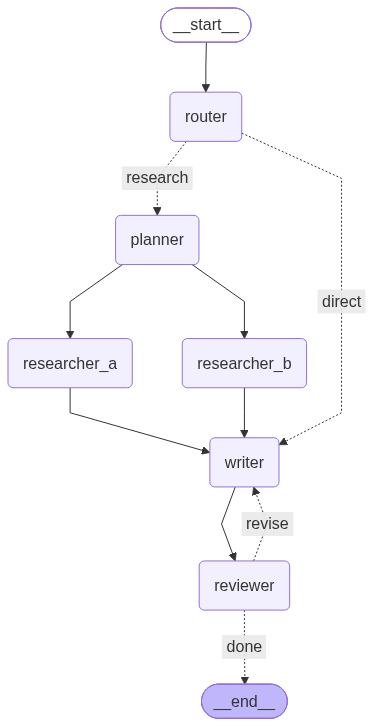

In [8]:
from IPython.display import Image, display
display(Image(app.get_graph().draw_mermaid_png()))

In [7]:
from google.colab import files
with open("workflow_diagram.png", "wb") as f:
    f.write(app.get_graph().draw_mermaid_png())
files.download("workflow_diagram.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>